# Quantile Machine Learning for VaR: QRF, LightGBM Quantile, CAViaR

A classical VaR engine models the whole return distribution and then reads the loss quantile off it. Validation teams increasingly add challenger models that forecast the quantile directly. The question is whether that extra flexibility gives a better-calibrated VaR, or just more ways to overfit. This notebook runs the comparison over eleven years of walk-forward forecasts.

**What it does.** It forecasts the daily 99% and 97.5% Value-at-Risk of a multi-asset portfolio directly as a conditional quantile, with machine-learning and econometric quantile models, and asks whether they beat the standard VaR engines out of sample.

**Data.** Daily total-return prices of an eight-ETF multi-asset portfolio (Yahoo Finance) and market indicators from FRED: VIX, Baa credit spread, 10-year Treasury yield and the 2s10s slope.

**Methods.** Linear quantile regression, the Quantile Random Forest (Meinshausen 2006), LightGBM with the quantile loss and the CAViaR asymmetric-slope model (Engle & Manganelli 2004), against historical simulation and GJR-GARCH-t, in an annual walk-forward from 2015 to 2026.

**Key output.** Pinball-loss rankings, coverage and independence tests including the Dynamic Quantile test, VaR paths through the 2020 and 2022 stress episodes, and what the models learn from market indicators.

## 1. Why model the quantile directly

A classical VaR engine models the *whole* return distribution, as a volatility times a shape, and reads the quantile off it. Model validation teams increasingly add **challenger models** that skip the distribution and forecast the quantile itself:

- **Quantile regression** fits the conditional quantile of tomorrow's return as a function of today's information, by minimising the *pinball loss*. That loss is exactly the scoring rule a quantile forecast should be judged by.
- **Tree ensembles** (QRF, LightGBM) learn non-linear interactions: high VIX *and* widening credit spreads may mean more than either alone.
- **CAViaR** keeps the autoregressive structure of GARCH but applies it to the quantile, with no distributional assumption.

The question for a validator: does the extra flexibility buy better-calibrated VaR, or just more ways to overfit?

## 2. The pinball loss and the tests

For a quantile level $\alpha$ and a forecast $q_t$, the **pinball (quantile) loss** is
$$
L_\alpha(r_t, q_t) = (\alpha - \mathbb{1}[r_t < q_t])\,(r_t - q_t).
$$
It is minimised in expectation by the true conditional quantile, so it ranks VaR forecasts fairly (lower is better).

**CAViaR, asymmetric slope:** $q_t = \beta_0 + \beta_1 q_{t-1} + \beta_2 \max(r_{t-1},0) + \beta_3 \min(r_{t-1},0)$, estimated by minimising the total pinball loss.

**Backtests** on hits $H_t = \mathbb{1}[r_t < q_t]$:

- **Kupiec:** is the hit rate equal to $\alpha$?
- **Christoffersen:** are hits independent from one day to the next?
- **Dynamic Quantile (DQ) test** (Engle & Manganelli): regress $H_t - \alpha$ on a constant, four lagged hits and the forecast itself. Under a correct model no regressor has power. The Wald statistic is $\chi^2_6$. It is the toughest of the three tests.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import statsmodels.api as sm
import yfinance as yf
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestRegressor
from statsmodels.regression.quantile_regression import QuantReg

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

WEIGHTS = {
    "SPY": 0.30,
    "IWM": 0.10,
    "EFA": 0.10,
    "TLT": 0.15,
    "IEF": 0.10,
    "LQD": 0.10,
    "HYG": 0.10,
    "GLD": 0.05,
}
TICKERS = list(WEIGHTS)
START = "2007-01-01"
# walk forward: re-estimate every January on all data to the previous December
FIRST_TEST_YEAR = 2015
# 99% VaR and the 97.5% level used by FRTB expected shortfall
QUANTILES = (0.01, 0.025)
PORTFOLIO_USD = 100_000_000
SEED = 8

print(f"LightGBM {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

LightGBM 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "Historical sim": PALETTE[1],
    "GJR-GARCH-t": PALETTE[3],
    "Linear QR": PALETTE[4],
    "QRF": PALETTE[2],
    "LightGBM quantile": PALETTE[0],
    "CAViaR (AS)": PALETTE[6],
}

## 4. Data and features

Every feature is known at the close of day $t$; the target is the portfolio return on day $t+1$.

| Feature | Meaning |
|---|---|
| `ret_1`, `ret_5` | portfolio return today and over five days |
| `vol_5`, `vol_22`, `vol_66` | realised volatility over one week, one month, one quarter |
| `downside_22` | volatility of negative days over a month |
| `ewma_vol` | RiskMetrics volatility (λ = 0.94) |
| `drawdown_22` | distance from the one-month high |
| `vix`, `d_vix_5` | VIX level and its five-day change |
| `d_credit_5` | five-day change in the Baa – 10Y spread (bp) |
| `d_10y_5`, `slope` | five-day change in the 10-year yield (bp) and the 2s10s slope |

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    if isinstance(px, pd.Series):
        px = px.to_frame(TICKERS[0])
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
# completed sessions only (no intraday row)
prices = prices[prices.index < pd.Timestamp.today().normalize()]
prices = prices.dropna(how="all").ffill(limit=3)

# --- Data cleaning: one-day bad prints that reverse the next day are replaced
# by interpolation
raw_ret = np.log(prices).diff()
# robust daily sigma
scale = raw_ret.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw_ret.abs() > 10 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
# A genuine crash-and-rebound (e.g. 12-13 Mar 2020) moves many assets at once;
# a bad print is idiosyncratic.
market_wide = (raw_ret.abs() > 4 * scale).sum(axis=1) >= 3
spike = (
    spike & ~market_wide.values[:, None]
    if prices.shape[1] >= 3
    else spike & False
)
for c in prices.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = np.log(prices).diff().dropna()
EVAL_DATE = returns.index.max()
print(
    f"{len(returns):,} trading days · {returns.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · {', '.join(prices.columns)}"
)

4,911 trading days · 2007-04-12 → 2026-10-16 · SPY, IWM, EFA, TLT, IEF, LQD, HYG, GLD


In [4]:
def fetch_fred():
    ids = ["VIXCLS", "BAA10Y", "DGS10", "T10Y2Y"]
    return pd.concat([
        pd.DataFrame({"date": s.index, "series": sid, "value": s.values})
        for sid in ids
        for s in [fred.get_series(sid, observation_start=START).dropna()]
    ])


macro = (
    cached("fred_market_indicators", fetch_fred)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
)
macro = macro.reindex(returns.index).ffill()
w = pd.Series(WEIGHTS)[returns.columns].values
port = pd.Series(np.expm1(returns) @ w, index=returns.index, name="port")

f = pd.DataFrame(index=port.index)
f["ret_1"] = port * 100
f["ret_5"] = port.rolling(5).sum() * 100
for n in (5, 22, 66):
    f[f"vol_{n}"] = port.rolling(n).std() * np.sqrt(252) * 100
f["downside_22"] = port.clip(upper=0).rolling(22).std() * np.sqrt(252) * 100
f["ewma_vol"] = (
    np.sqrt(port.pow(2).ewm(alpha=0.06, adjust=False).mean())
    * np.sqrt(252)
    * 100
)
wealth = (1 + port).cumprod()
f["drawdown_22"] = (wealth / wealth.rolling(22).max() - 1) * 100
f["vix"] = macro["VIXCLS"]
f["d_vix_5"] = macro["VIXCLS"].diff(5)
f["d_credit_5"] = macro["BAA10Y"].diff(5) * 100
f["d_10y_5"] = macro["DGS10"].diff(5) * 100
f["slope"] = macro["T10Y2Y"]
FEATS = list(f.columns)
data = f.join(port.shift(-1).rename("target")).dropna()
print(
    f"{len(data):,} days with features · {data.index.min():%Y-%m-%d} →"
    f" {data.index.max():%Y-%m-%d} · test from"
    f" {FIRST_TEST_YEAR} ({(data.index.year >= FIRST_TEST_YEAR).sum():,} days)"
)

4,845 days with features · 2007-07-16 → 2026-10-15 · test from 2015 (2,964 days)


## 5. The models

**QRF from scratch.** Meinshausen's Quantile Random Forest is a random forest whose prediction is not the mean of the training targets in the leaves but their **weighted empirical distribution**. A training point gets weight $1/|\text{leaf}|$ in every tree where it shares a leaf with the test point.

The forest below is scikit-learn's; the quantile step is twenty lines of numpy. Large leaves (at least 40 days) keep the tail quantiles estimable.

In [5]:
def qrf_quantiles(forest, X_train, y_train, X_test, qs):
    """
    Meinshausen (2006): weighted empirical quantiles from leaf co-membership
    across trees.
    """
    leaves_tr, leaves_te = forest.apply(X_train), forest.apply(X_test)
    W = np.zeros((len(X_test), len(X_train)))
    for t in range(leaves_tr.shape[1]):
        same = leaves_te[:, t][:, None] == leaves_tr[:, t][None, :]
        W += same / same.sum(axis=1, keepdims=True)
    W /= leaves_tr.shape[1]
    order = np.argsort(y_train)
    cw = np.cumsum(W[:, order], axis=1)
    return {q: y_train[order][np.argmax(cw >= q, axis=1)] for q in qs}


def caviar_path(beta, r, q0):
    q = np.empty(len(r))
    q[0] = q0
    for t in range(1, len(r)):
        q[t] = (
            beta[0]
            + beta[1] * q[t - 1]
            + beta[2] * max(r[t - 1], 0)
            + beta[3] * min(r[t - 1], 0)
        )
    return q


def pinball(r, q, a):
    return np.mean((a - (r < q)) * (r - q))


def fit_caviar(r, a, rng, warm=None):
    """
    Random search for good starts (plus last year's solution), then Nelder–Mead
    on the total pinball loss.
    """
    q0 = np.quantile(r[:300], a)
    loss = lambda b: (
        pinball(r, caviar_path(b, r, q0), a) if abs(b[1]) < 1 else 1e6
    )
    cands = list(
        np.column_stack([
            rng.uniform(-0.002, 0.0, 150),
            rng.uniform(0.6, 0.99, 150),
            rng.uniform(-0.6, 0.3, 150),
            rng.uniform(0.0, 1.2, 150),
        ])
    )
    if warm is not None:
        cands.append(warm)
    best = sorted(cands, key=loss)[:3]
    fits = [
        minimize(
            loss,
            b,
            method="Nelder-Mead",
            options={"maxiter": 1000, "xatol": 1e-7, "fatol": 1e-10},
        )
        for b in best
    ]
    return min(fits, key=lambda z: z.fun).x, q0

### 5.1 Walk-forward estimation

Each January every model is re-estimated on all data up to the previous December and then forecasts every day of the year. Historical simulation uses a rolling 500-day window; GJR-GARCH is filtered daily with that year's parameters. This takes a few minutes, mostly for the forest weights and the CAViaR optimisation.

In [6]:
rng = np.random.default_rng(SEED)
rows, caviar_warm = [], {}
# return of day t+1, indexed by t
r_all = data["target"]
port_all = port.loc[: data.index.max()]
for year in range(FIRST_TEST_YEAR, data.index.year.max() + 1):
    tr = data[data.index.year < year]
    te = data[data.index.year == year]
    Xtr, ytr, Xte = tr[FEATS].values, tr["target"].values, te[FEATS].values
    out = pd.DataFrame(index=te.index)

    # Historical simulation: last 500 returns known at t
    hs = port_all.rolling(500)
    for a in QUANTILES:
        out[("Historical sim", a)] = hs.quantile(a).reindex(te.index).values

    # GJR-GARCH-t: parameters from the training years, filtered through the
    # test year
    r100 = port_all.loc[: te.index[-1]] * 100
    g = arch_model(
        r100.loc[: tr.index[-1]],
        mean="Constant",
        vol="GARCH",
        p=1,
        o=1,
        q=1,
        dist="t",
    ).fit(disp="off")
    fixed = arch_model(
        r100, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t"
    ).fix(g.params)
    fc = fixed.forecast(horizon=1, start=te.index[0], reindex=False)
    sig, mu, nu = (
        np.sqrt(fc.variance["h.1"].reindex(te.index).values),
        g.params["mu"],
        g.params["nu"],
    )
    for a in QUANTILES:
        out[("GJR-GARCH-t", a)] = (
            mu + sig * stats.t.ppf(a, nu) * np.sqrt((nu - 2) / nu)
        ) / 100

    # Linear quantile regression
    for a in QUANTILES:
        qr = QuantReg(ytr, sm.add_constant(Xtr)).fit(q=a, max_iter=5000)
        out[("Linear QR", a)] = qr.predict(
            sm.add_constant(Xte, has_constant="add")
        )

    # Quantile Random Forest
    rf = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=40,
        max_features=0.5,
        random_state=SEED,
        n_jobs=-1,
    )
    rf.fit(Xtr, ytr)
    for a, qv in qrf_quantiles(rf, Xtr, ytr, Xte, QUANTILES).items():
        out[("QRF", a)] = qv

    # LightGBM with the quantile (pinball) objective, one model per level
    for a in QUANTILES:
        m = lgb.LGBMRegressor(
            objective="quantile",
            alpha=a,
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=8,
            min_child_samples=80,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            random_state=SEED,
            verbose=-1,
        )
        m.fit(Xtr, ytr)
        out[("LightGBM quantile", a)] = m.predict(Xte)

    # CAViaR asymmetric slope on the portfolio return series
    r_tr = port_all.loc[: tr.index[-1]].values
    r_full = port_all.loc[: te.index[-1]].values
    for a in QUANTILES:
        beta, q0 = fit_caviar(r_tr, a, rng, caviar_warm.get(a))
        caviar_warm[a] = beta
        # path[t] = quantile of the return on day t
        path = caviar_path(beta, r_full, q0)
        # the forecast made at the close of day t is for day t+1: one more step
        # of the recursion
        step = (
            beta[0]
            + beta[1] * path
            + beta[2] * np.maximum(r_full, 0)
            + beta[3] * np.minimum(r_full, 0)
        )
        out[("CAViaR (AS)", a)] = (
            pd.Series(step, index=port_all.loc[: te.index[-1]].index)
            .reindex(te.index)
            .values
        )
    out["realised"] = te["target"].values
    rows.append(out)
    print(f"{year}: trained on {len(tr):,} days, forecast {len(te)} days")

fc_all = pd.concat(rows)
realised = fc_all.pop("realised")
fc_all.columns = pd.MultiIndex.from_tuples(
    fc_all.columns, names=["model", "alpha"]
)

2015: trained on 1,881 days, forecast 252 days


2016: trained on 2,133 days, forecast 252 days


2017: trained on 2,385 days, forecast 251 days


2018: trained on 2,636 days, forecast 251 days


2019: trained on 2,887 days, forecast 252 days


2020: trained on 3,139 days, forecast 253 days


... (2 outputs left out)

2023: trained on 3,895 days, forecast 250 days


2024: trained on 4,145 days, forecast 252 days


2025: trained on 4,397 days, forecast 250 days


2026: trained on 4,647 days, forecast 198 days


## 6. Out-of-sample evaluation, 2015–2026

In [7]:
def kupiec(h, a):
    x, n = h.sum(), len(h)
    if x == 0:
        lr = -2 * n * np.log(1 - a)
    else:
        p = x / n
        lr = -2 * (
            (n - x) * np.log(1 - a)
            + x * np.log(a)
            - (n - x) * np.log(1 - p)
            - x * np.log(p)
        )
    return 1 - stats.chi2.cdf(lr, 1)


def christoffersen(h):
    h = np.asarray(h, int)
    n = {
        (i, j): np.sum((h[:-1] == i) & (h[1:] == j))
        for i in (0, 1)
        for j in (0, 1)
    }
    p01, p11 = n[0, 1] / max(n[0, 0] + n[0, 1], 1), n[1, 1] / max(
        n[1, 0] + n[1, 1], 1
    )
    p = (n[0, 1] + n[1, 1]) / max(sum(n.values()), 1)
    ll = lambda q, a, b: (a * np.log(1 - q) if a else 0) + (
        b * np.log(q) if b and q > 0 else 0
    )
    lr = -2 * (
        ll(p, n[0, 0] + n[1, 0], n[0, 1] + n[1, 1])
        - ll(p01, n[0, 0], n[0, 1])
        - ll(p11, n[1, 0], n[1, 1])
    )
    return 1 - stats.chi2.cdf(lr, 1)


def dq_test(h, q, a, lags=4):
    """
    Engle–Manganelli Dynamic Quantile test: Wald test that Hit − α is
    unpredictable.
    """
    hit = h.astype(float) - a
    X = np.column_stack(
        [np.ones(len(hit))]
        + [np.r_[np.zeros(k), hit[:-k]] for k in range(1, lags + 1)]
        + [q]
    )[lags:]
    y = hit[lags:]
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    stat = beta @ X.T @ X @ beta / (a * (1 - a))
    return 1 - stats.chi2.cdf(stat, X.shape[1])


res = []
for (m, a), q in fc_all.items():
    ok = q.notna()
    h = (realised[ok] < q[ok]).values
    res.append({
        "model": m,
        "VaR level": f"{1 - a:.1%}",
        "pinball ×1e4": pinball(realised[ok].values, q[ok].values, a) * 1e4,
        "hits": h.sum(),
        "expected": len(h) * a,
        "hit rate %": h.mean() * 100,
        "Kupiec p": kupiec(h, a),
        "Christoffersen p": christoffersen(h),
        "DQ p": dq_test(h, q[ok].values, a),
        "avg VaR $mm": -q[ok].mean() * PORTFOLIO_USD / 1e6,
    })
scores = (
    pd.DataFrame(res)
    .set_index(["VaR level", "model"])
    .sort_values(["VaR level", "pinball ×1e4"])
)
scores["passes all 3"] = (
    (scores[["Kupiec p", "Christoffersen p", "DQ p"]] > 0.05)
    .all(axis=1)
    .map({True: "✅", False: "—"})
)
scores.round(3)

pinball ×1e4  hits  expected  hit rate %  \
VaR level model                                                         
97.5%     Linear QR                  3.90    89     74.10        3.00   
          GJR-GARCH-t                4.05    91     74.10        3.07   
          CAViaR (AS)                4.09    71     74.10        2.40   
          QRF                        4.12    55     74.10        1.86   
          LightGBM quantile          4.13   105     74.10        3.54   
          Historical sim             4.81    96     74.10        3.24   
99.0%     CAViaR (AS)                1.95    28     29.64        0.94   
          GJR-GARCH-t                2.02    47     29.64        1.59   
          Linear QR                  2.04    44     29.64        1.48   
          QRF                        2.04    24     29.64        0.81   
          LightGBM quantile          2.12    59     29.64        1.99   
          Historical sim             2.90    36     29.64        1.22   

                             Kupiec p  Christoffersen p  DQ p  avg VaR $mm  \
VaR level model                                                              
97.5%     Linear QR              0.09              0.07  0.05         1.09   
          GJR-GARCH-t            0.06              0.03  0.00         1.10   
          CAViaR (AS)            0.71              0.03  0.15         1.19   
          QRF                    0.02              0.02  0.00         1.28   
          LightGBM quantile      0.00              0.01  0.00         1.04   
          Historical sim         0.01              0.00  0.00         1.14   
99.0%     CAViaR (AS)            0.76              0.27  0.57         1.52   
          GJR-GARCH-t            0.00              0.22  0.02         1.40   
          Linear QR              0.01              0.17  0.01         1.41   
          QRF                    0.28              0.53  0.32         1.69   
          LightGBM quantile      0.00              0.15  0.00         1.27   
          Historical sim         0.26              0.00  0.00         1.68   

                            passes all 3  
VaR level model                           
97.5%     Linear QR                    ✅  
          GJR-GARCH-t                  —  
          CAViaR (AS)                  —  
          QRF                          —  
          LightGBM quantile            —  
          Historical sim               —  
99.0%     CAViaR (AS)                  ✅  
          GJR-GARCH-t                  —  
          Linear QR                    —  
          QRF                          ✅  
          LightGBM quantile            —  
          Historical sim               —

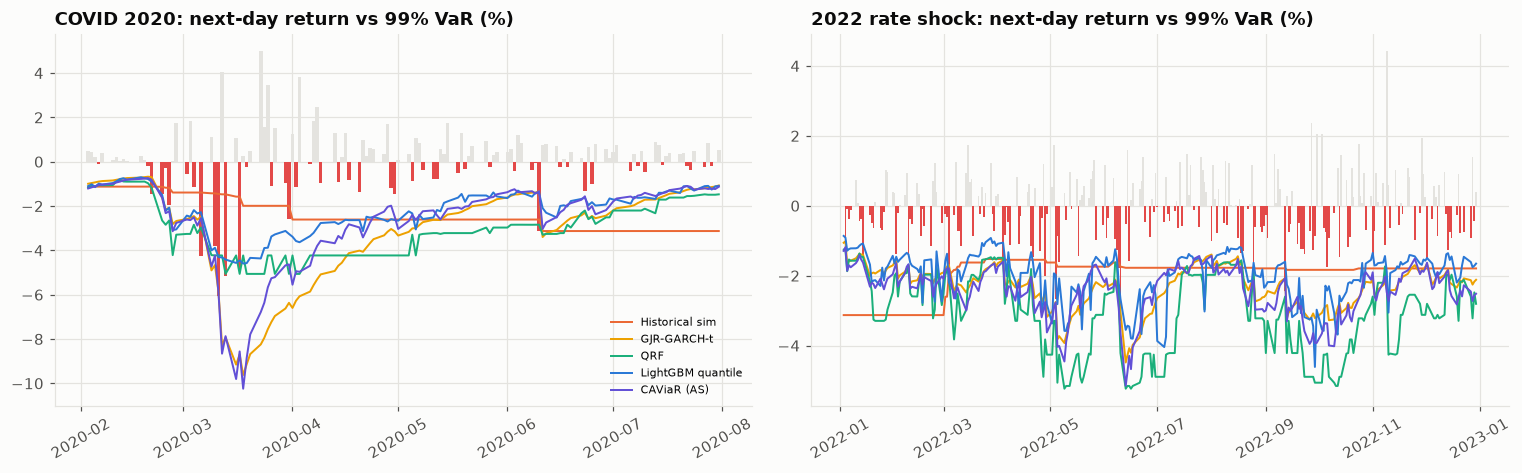

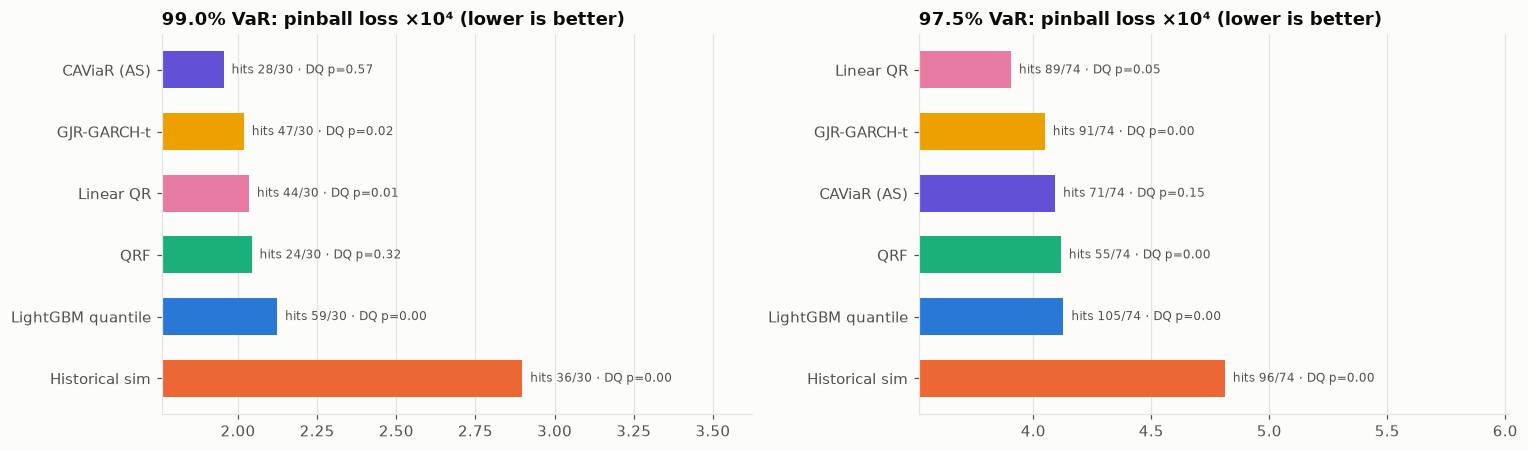

In [8]:
# --- Chart 1: 99% VaR through two stress episodes
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, (a_, b_, title) in zip(
    axes,
    [
        ("2020-02-01", "2020-07-31", "COVID 2020"),
        ("2022-01-01", "2022-12-31", "2022 rate shock"),
    ],
):
    r = realised.loc[a_:b_] * 100
    ax.bar(
        r.index,
        r.values,
        color=[STATUS["red"] if v < 0 else GRID for v in r.values],
        width=1,
    )
    for m in [
        "Historical sim",
        "GJR-GARCH-t",
        "QRF",
        "LightGBM quantile",
        "CAViaR (AS)",
    ]:
        ax.plot(
            r.index,
            fc_all[(m, 0.01)].loc[a_:b_] * 100,
            color=MODEL_COLORS[m],
            lw=1.3,
            label=m,
        )
    ax.set_title(f"{title}: next-day return vs 99% VaR (%)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
save_fig(fig, "01_var_paths_stress")
plt.show()

# --- Chart 2: pinball loss and coverage by model
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, lvl in zip(axes, ["99.0%", "97.5%"]):
    s = scores.loc[lvl].sort_values("pinball ×1e4", ascending=False)
    ax.barh(
        s.index,
        s["pinball ×1e4"],
        color=[MODEL_COLORS[m] for m in s.index],
        height=0.6,
    )
    for y, (m, r_) in enumerate(s.iterrows()):
        ax.text(
            r_["pinball ×1e4"],
            y,
            f"  hits {r_['hits']}/{r_['expected']:.0f} · DQ"
            f" p={r_['DQ p']:.2f}",
            va="center",
            fontsize=8,
            color=INK_2,
        )
    ax.set_xlim(s["pinball ×1e4"].min() * 0.9, s["pinball ×1e4"].max() * 1.25)
    ax.set_title(f"{lvl} VaR: pinball loss ×10⁴ (lower is better)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "02_pinball_and_coverage")
plt.show()

### 6.1 What do the machine-learning models look at?

LightGBM's split-gain importance from the last training year, and the coefficients of the linear quantile regression on standardised features at the 99% level: a negative coefficient means the feature pushes the 1% quantile further down (more risk).

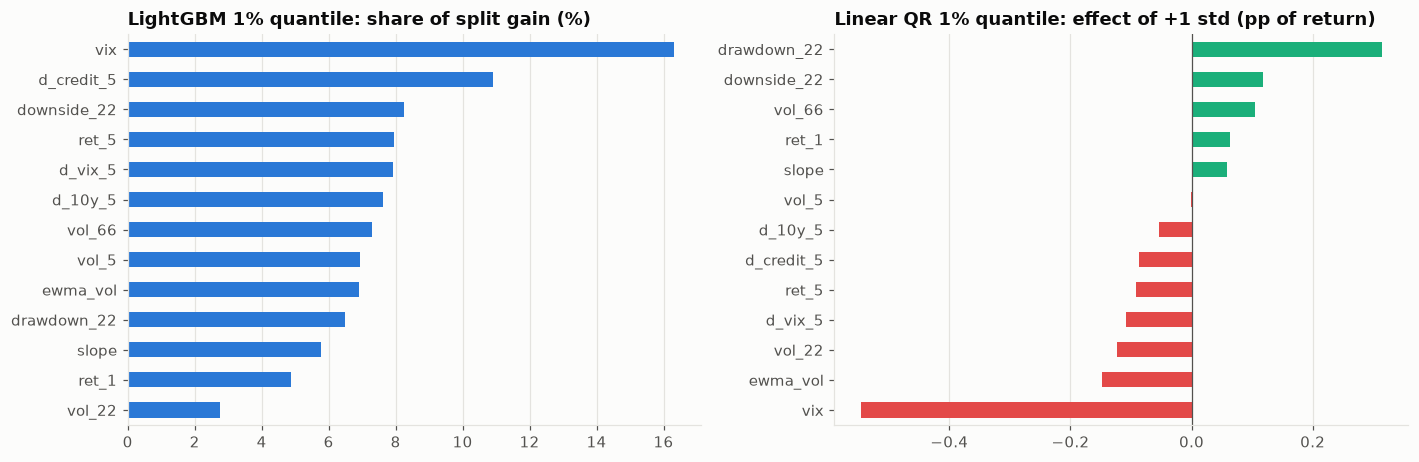

,VaR 99.0% ($mm),VaR 97.5% ($mm)
model,,
CAViaR (AS),1.36,1.04
GJR-GARCH-t,1.24,0.98
Historical sim,1.70,1.17
LightGBM quantile,1.30,1.14
Linear QR,1.26,0.96
QRF,1.42,1.09


In [9]:
last_tr = data[data.index.year < data.index.year.max()]
gbm = lgb.LGBMRegressor(
    objective="quantile",
    alpha=0.01,
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=8,
    min_child_samples=80,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
    importance_type="gain",
).fit(last_tr[FEATS], last_tr["target"])
imp = pd.Series(gbm.feature_importances_, index=FEATS)
imp = imp / imp.sum() * 100
Xs = (last_tr[FEATS] - last_tr[FEATS].mean()) / last_tr[FEATS].std()
qr = QuantReg(last_tr["target"] * 100, sm.add_constant(Xs)).fit(
    q=0.01, max_iter=5000
)
coef = qr.params.drop("const")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
imp.sort_values().plot.barh(ax=axes[0], color=PALETTE[0])
axes[0].set_title("LightGBM 1% quantile: share of split gain (%)")
coef.sort_values().plot.barh(
    ax=axes[1],
    color=[STATUS["red"] if v < 0 else PALETTE[2] for v in coef.sort_values()],
)
axes[1].axvline(0, color=INK_2, lw=0.8)
axes[1].set_title("Linear QR 1% quantile: effect of +1 std (pp of return)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "03_what_the_models_learn")
plt.show()

scores.to_csv(OUT_DIR / "quantile_var_scores.csv")
fc_all.assign(realised=realised).to_csv(
    OUT_DIR / "var_forecasts_walk_forward.csv"
)
today = fc_all.iloc[-1].unstack("alpha") * -PORTFOLIO_USD / 1e6
today.columns = [f"VaR {1 - a:.1%} ($mm)" for a in today.columns]
today.round(2)

## 7. Reading the results and limitations

**What the walk-forward says**

**There is no single winner, and the one that wins is not the most flexible.** At 99%, **CAViaR** has the lowest pinball loss and passes all three tests: its autoregressive quantile adapts quickly without any distributional assumption. **QRF** also passes all three but is conservative, with fewer hits than expected and a higher average VaR.

At 97.5% the plain **linear quantile regression** on market indicators ranks first and passes, though its DQ p-value is borderline.

**LightGBM with the quantile loss is the worst calibrated.** It has about twice the expected hits at 99%. Gradient boosting on the pinball loss learns the tail slowly: at the 1% level the gradient is non-zero for very few observations, so the trees mostly fit the body of the distribution.

Tuning (fewer, larger leaves; more trees) helps less than one would hope. This is a known weakness worth documenting in a validation report.

- **The parametric GJR-GARCH-t is too thin-tailed at 99%** (about 1.6% hits), unlike filtered historical simulation (FHS) with the same volatility model. The empirical residuals of FHS matter.
- **Historical simulation** has a correct count but clustered hits, and a pinball loss far above every conditional model. Conditioning on today's market state is worth more than any particular algorithm.

**What the ML models look at:** the VIX dominates in both models, and the five-day change in the credit spread is LightGBM's second most useful feature. Markets price stress before realised volatility shows it. In the linear quantile regression a recent drawdown *raises* the 1% quantile once the VIX is controlled for: after a fall, some of the risk is already in the price.

**For a model-risk committee**, a reasonable conclusion: keep a conditional econometric model (FHS-GARCH or CAViaR) as champion, run QRF as a challenger whose conservative bias is known, and do not use boosted quantile models for the 99% tail without a calibration layer.

**Limitations**

- **Annual re-estimation** with fixed hyper-parameters (leaf sizes, learning rate) chosen for stability, not tuned on the test years.
- **Linear quantile regressions are estimated separately for each level**, so in principle the 99% and 97.5% forecasts can cross. A joint or monotone fit would prevent it.
- **One portfolio.** A validator would repeat the exercise on desk-level portfolios and on hypothetical P&L.

## References

### Finance and regulation

- Engle, R. F., & Manganelli, S. (2004). CAViaR: Conditional autoregressive value at risk by regression quantiles. *Journal of Business & Economic Statistics, 22*(4), 367–381. https://doi.org/10.1198/073500104000000370
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review, 39*(4), 841–862. https://doi.org/10.2307/2527341
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *The Journal of Finance, 48*(5), 1779–1801. https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Gneiting, T. (2011). Making and evaluating point forecasts. *Journal of the American Statistical Association, 106*(494), 746–762. https://doi.org/10.1198/jasa.2011.r10138

### Machine learning and deep learning

- Koenker, R., & Bassett, G. (1978). Regression quantiles. *Econometrica, 46*(1), 33–50. https://doi.org/10.2307/1913643
- Meinshausen, N. (2006). Quantile regression forests. *Journal of Machine Learning Research, 7*, 983–999. https://jmlr.org/papers/v7/meinshausen06a.html
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html